# Qwen3-1.7B: Teacher Distillation, SFT, and GRPO

Teacher: **DeepSeek-R1-Distill-Llama-8B**. Student: **Qwen3-1.7B-Base**.

Defaults: **128 teacher candidate questions**, **one SFT epoch**, **128 separate RL questions**, **64 GRPO optimizer updates**, **32 development questions**, and **64 fixed test questions**.

Upload the complete project folder to `MyDrive/qwen3_1p7b_128_en` before opening this notebook in Colab. Run cells in order. Use a new experiment directory; do not reuse old adapters or result files. GPU execution has not been tested locally. Read `README.md` for limitations and resource requirements.


In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, json, subprocess, time
from pathlib import Path
PROJECT = Path('/content/drive/MyDrive/qwen3_1p7b_128_en')
assert (PROJECT/'pipeline.py').exists(), f'Upload the full project to {PROJECT}'
os.chdir(PROJECT)
print('Project:', PROJECT)


Mounted at /content/drive
Project: /content/drive/MyDrive/qwen3_1p7b_128_en


In [2]:
subprocess.run(['nvidia-smi'], check=True)
import torch
assert torch.cuda.is_available(), 'Select a GPU runtime.'
assert torch.cuda.is_bf16_supported(), 'This profile requires BF16 support.'
print('GPU:', torch.cuda.get_device_name())
print('VRAM GiB:', round(torch.cuda.get_device_properties(0).total_memory/2**30, 2))
print('PyTorch:', torch.__version__, 'CUDA:', torch.version.cuda)


GPU: NVIDIA L4
VRAM GiB: 22.03
PyTorch: 2.11.0+cu130 CUDA: 13.0


## Install and check dependencies

The optional compatibility repair below removes unused Gradio/Diffusers packages and aligns the known Colab dependency conflicts. It does not delete data or model caches. If Colab requests a restart, restart the session, then rerun mount, hardware, and configuration cells. Do not delete the runtime. Console output streams as commands execute.


In [3]:
def stream_command(command, env=None, log_path=None):
    print('Running:', ' '.join(map(str, command)), flush=True)
    handle = open(log_path, 'a', encoding='utf-8') if log_path else None
    process = subprocess.Popen(
        list(map(str, command)), stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, env=env, cwd=PROJECT)
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
            if handle:
                handle.write(line)
                handle.flush()
        result = process.wait()
        if result:
            raise RuntimeError(f'Command failed with exit code {result}. Read the output above. Log: {log_path}')
    except BaseException:
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=20)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        raise
    finally:
        if handle:
            handle.close()

REPAIR_COLAB_PACKAGES = True
if REPAIR_COLAB_PACKAGES:
    stream_command([sys.executable, '-u', 'repair_colab.py'])
else:
    stream_command([sys.executable, '-m', 'pip', 'install', '-r', 'requirements.txt'])
stream_command([sys.executable, '-m', 'pip', 'check'])
stream_command([sys.executable, '-m', 'unittest', '-v', 'test_core.py'])
stream_command([sys.executable, '-c',
    'from transformers import Trainer; from peft import PeftModel; from trl import GRPOTrainer; print("Training imports OK")'])


Running: /usr/bin/python3 -u repair_colab.py
This project does not use gradio or diffusers; removing them from this Colab runtime.
Found existing installation: gradio 6.29.0
Uninstalling gradio-6.29.0:
  Successfully uninstalled gradio-6.29.0
Found existing installation: diffusers 0.40.0
Uninstalling diffusers-0.40.0:
  Successfully uninstalled diffusers-0.40.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 89.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 137.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 564.6/564.6 kB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 503.6/503.6 kB 52.3 MB/s eta 0

## Configure the experiment

`SFT_STEPS=-1` means exactly one epoch over accepted samples. `RL_STEPS=64` means 64 optimizer updates, not 64 epochs. Teacher filtering may leave fewer than 128 SFT samples. Separate model caches keep teacher and student downloads organized. The teacher cache is retained by default for optional teacher evaluation.


In [4]:
ROOT = PROJECT/'runs'/'ds8b_qwen1p7b_128_001'
ROOT.mkdir(parents=True, exist_ok=True)
(ROOT/'logs').mkdir(exist_ok=True)
SFT_N, RL_N, DEV_N, TEST_N = 128, 128, 32, 64
SFT_STEPS, RL_STEPS = -1, 64
TEACHER_TOKENS, SEQ_LEN, RL_TOKENS, EVAL_TOKENS = 4096, 4096, 2048, 2048
SAVE_STEPS = 16
TEACHER_CACHE = Path('/content/ds8b_teacher_cache')
STUDENT_CACHE = Path('/content/qwen1p7b_student_cache')

def run(*args, teacher=False, script='pipeline.py'):
    env = dict(os.environ)
    env['HF_HOME'] = str(TEACHER_CACHE if teacher else STUDENT_CACHE)
    env['TOKENIZERS_PARALLELISM'] = 'false'
    env['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
    label = Path(script).stem + ('_'+str(args[0]) if args and script == 'pipeline.py' else '')
    logfile = ROOT/'logs'/f'{label}_{time.time_ns()}.console.log'
    command = [sys.executable, '-u', script, *map(str, args), '--root', str(ROOT)]
    print('Console log:', logfile)
    stream_command(command, env=env, log_path=logfile)

(ROOT/'environment.txt').write_text(subprocess.check_output(
    [sys.executable, '-m', 'pip', 'freeze'], text=True), encoding='utf-8')
(ROOT/'hardware.json').write_text(json.dumps({
    'torch': torch.__version__, 'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name(),
    'vram_bytes': torch.cuda.get_device_properties(0).total_memory}, indent=2), encoding='utf-8')
print('Experiment:', ROOT)


Experiment: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001


In [5]:
if not (ROOT/'manifest.json').exists():
    run('prepare', '--sft-n', SFT_N, '--rl-n', RL_N, '--dev-n', DEV_N, '--test-n', TEST_N)
else:
    manifest = json.loads((ROOT/'manifest.json').read_text())
    expected = {'sft_questions': SFT_N, 'rl': RL_N, 'dev': DEV_N, 'test_gsm8k': TEST_N}
    assert all(manifest['counts'].get(k) == v for k, v in expected.items()), 'Saved split sizes differ. Use a new ROOT.'
    print('Reusing the saved dataset splits:', manifest['counts'])


Console log: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/logs/pipeline_prepare_1792114791424899951.console.log
Running: /usr/bin/python3 -u pipeline.py prepare --sft-n 128 --rl-n 128 --dev-n 32 --test-n 64 --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001

Generating train split: 100%|██████████| 7473/7473 [00:00<00:00, 232013.04 examples/s]

Generating test split: 100%|██████████| 1319/1319 [00:00<00:00, 277850.78 examples/s]

Generating test split: 0 examples [00:00, ? examples/s]
Generating test split: 500 examples [00:00, 95904.88 examples/s]
{
  "seed": 42,
  "dataset_revisions": {
    "openai/gsm8k": "740312add88f781978c0658806c59bc2815b9866",
    "HuggingFaceH4/MATH-500": "6e4ed1a2a79af7d8630a6b768ec859cb5af4d3be"
  },
  "model_revisions": {
    "Qwen/Qwen3-1.7B-Base": "ea980cb0a6c2ae4b936e82123acc929f1cec04c1",
    "deepseek-ai/DeepSeek-R1-Distill-Llama-8B": "6a6f4aa4197940add57724a7707d069478df56b1"
  },
  "counts": {
    "sft_q

## Generate teacher traces

The teacher processes 128 questions with at most two attempts per question. Progress counts completed questions, not tokens. Each attempt and its duration are printed; each question updates the progress bar, accepted count, and ETA. Generation output is saved immediately to Drive so rerunning skips completed work. Downloading/loading weights occurs before generation progress advances.


In [6]:
import shutil
from huggingface_hub import HfApi
teacher_id = 'deepseek-ai/DeepSeek-R1-Distill-Llama-8B'
manifest = json.loads((ROOT/'manifest.json').read_text())
info = HfApi().model_info(teacher_id, revision=manifest['model_revisions'][teacher_id], files_metadata=True)
weight_bytes = sum(f.size or 0 for f in info.siblings if f.rfilename.endswith('.safetensors'))
TEACHER_CACHE.mkdir(parents=True, exist_ok=True)
blobs = TEACHER_CACHE/'hub'/('models--'+teacher_id.replace('/', '--'))/'blobs'
already = sum(p.stat().st_size for p in blobs.glob('*') if p.is_file()) if blobs.exists() else 0
free = shutil.disk_usage(TEACHER_CACHE).free
needed = max(0, weight_bytes-already)+2*2**30
print('Teacher weight GiB:', round(weight_bytes/2**30, 2))
print('Free disk GiB:', round(free/2**30, 2), 'Estimated additional GiB:', round(needed/2**30, 2))
assert free >= needed, 'Insufficient disk space. Free unused caches or choose a larger cache disk.'
run('teacher', '--attempts', 2, '--teacher-tokens', TEACHER_TOKENS, teacher=True)
run('build', '--seq-len', SEQ_LEN)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Teacher weight GiB: 14.96
Free disk GiB: 70.04 Estimated additional GiB: 16.96
Console log: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/logs/pipeline_teacher_1792114804601394564.console.log
Running: /usr/bin/python3 -u pipeline.py teacher --attempts 2 --teacher-tokens 4096 --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001
I0000 00:00:1792114807.634113    3050 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792114807.704157    3050 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792114810.131312  

In [7]:
from pipeline import read
attempts = read(ROOT/'data'/'teacher_attempts.jsonl')
accepted = [r for r in attempts if r['accepted']]
sft_rows = read(ROOT/'data'/'sft.jsonl')
print('Generation attempts:', len(attempts))
print('Accepted questions:', len({r['id'] for r in accepted}), '/', SFT_N)
print('SFT samples after length filtering:', len(sft_rows))
print('Total teacher generation seconds:', round(sum(r['seconds'] for r in attempts)))
print('Coverage after retries is NOT independent test accuracy.')
assert len(sft_rows) >= 4, 'Too few usable samples. Inspect failures and truncation before training.'
print('Sample trace (first 4000 characters):')
print(sft_rows[0]['completion'][:4000])


Generation attempts: 162
Accepted questions: 111 / 128
SFT samples after length filtering: 111
Total teacher generation seconds: 4673
Coverage after retries is NOT independent test accuracy.
Sample trace (first 4000 characters):
First, I need to calculate the cost of the appetizer and the entrees.

The appetizer costs $10.

Each of the 4 entrees costs $20, so the total for the entrees is 4 multiplied by $20, which equals $80.

Next, I'll add the cost of the appetizer and the entrees together to find the total pre-tip amount: $10 + $80 = $90.

Then, I'll calculate the tip. The tip is 20% of the total pre-tip amount, which is 0.20 multiplied by $90, resulting in $18.

Finally, I'll add the tip to the total pre-tip amount to determine the total amount spent at the restaurant: $90 + $18 = $108.


Let's break down the problem step by step to find the total amount Stefan and his family spend at the restaurant.

1. **Calculate the cost of the appetizer:**
   \[
   \text{Appetizer} = \$10
   \

## Optional: evaluate the teacher

Uses the same saved 64 test questions, greedy decoding, a 2048-token budget, and the same answer verifier as student evaluation. Leave disabled to save time. This is independent test accuracy, unlike training-data coverage after retries.


In [8]:
RUN_TEACHER_EVAL = False
if RUN_TEACHER_EVAL:
    run('--max-new-tokens', EVAL_TOKENS, teacher=True, script='eval_teacher.py')


## Optional: clean only this project's teacher cache

The teacher process has exited, so its GPU memory is released regardless of whether the disk cache is retained. Keep the cache to avoid redownloading weights. If enabled below, cleanup deletes only the exact known local teacher cache directory after verifying that SFT data was saved. It does not delete Drive data, adapters, logs, or old 32B caches.


In [ ]:
DELETE_TEACHER_CACHE = False
expected = Path('/content/ds8b_teacher_cache')
if DELETE_TEACHER_CACHE:
    assert TEACHER_CACHE.resolve() == expected.resolve(), 'Unexpected cache path; cleanup stopped.'
    assert (ROOT/'data'/'sft.jsonl').stat().st_size > 0
    if expected.exists():
        shutil.rmtree(expected)
    print('Local teacher cache removed; generated data remains on Drive.')
print('Free local disk GiB:', round(shutil.disk_usage('/content').free/2**30, 2))


## SFT: one epoch

The progress display reports optimizer updates, percentage, loss, learning rate, epoch, GPU memory, elapsed time, and ETA. With 128 accepted samples and accumulation 8, one epoch is about 16 updates. Filtering may reduce that number. Logs and checkpoints are written to Drive.


In [9]:
run('sft', '--seq-len', SEQ_LEN, '--steps', SFT_STEPS, '--save-steps', SAVE_STEPS)
run('eval', '--stage', 'sft', '--split', 'dev', '--eval-tokens', EVAL_TOKENS)


Console log: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/logs/pipeline_sft_1792119559485356459.console.log
Running: /usr/bin/python3 -u pipeline.py sft --seq-len 4096 --steps -1 --save-steps 16 --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001
I0000 00:00:1792119565.036217   23809 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792119565.111986   23809 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792119567.554536   23809 port.cc:153] oneDNN custom operations are on. You may see slightly differ

## GRPO: 64 optimizer updates

Continue the SFT LoRA adapter using 128 separate RL questions. Each question produces four sampled completions. The reward is numeric correctness only; beta=0 means no KL penalty. Each update prints TRL metrics, including reward statistics when available, plus elapsed time, ETA, and GPU memory. The first update can take longer because answers must be generated first. Checkpoints are saved at updates 16, 32, 48, and 64; only the latest three are retained.


In [14]:
run('grpo', '--steps', RL_STEPS, '--rl-tokens', RL_TOKENS, '--save-steps', SAVE_STEPS)
run('eval', '--stage', 'grpo', '--split', 'dev', '--eval-tokens', EVAL_TOKENS)


Console log: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/logs/pipeline_grpo_1792125667390087935.console.log
Running: /usr/bin/python3 -u pipeline.py grpo --steps 64 --rl-tokens 2048 --save-steps 16 --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001
I0000 00:00:1792125673.040331   50634 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792125673.114878   50634 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792125675.585806   50634 port.cc:153] oneDNN custom operations are on. You may see slightly di

## Inspect progress and training curves

Console output shows progress while training runs. This cell reads persisted logs after the running cell finishes or is interrupted. To resume GRPO from an existing checkpoint, use `run('grpo', '--steps', 64, '--resume', ROOT/'grpo'/'checkpoint-32')`, adjusting the checkpoint path to one that exists. The target stays 64 total updates.


Console log: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/logs/inspect_run_1792132179525738792.console.log
Running: /usr/bin/python3 -u inspect_run.py --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001
Experiment: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001
Dataset sizes: {'sft_questions': 128, 'rl': 128, 'dev': 32, 'test_gsm8k': 64, 'test_math500': 500}
sft_questions: 128 records
teacher_attempts: 162 records
sft: 111 records
rl: 128 records
dev: 32 records
test_gsm8k: 64 records

Latest saved progress:
eval_base_test_gsm8k_metrics.jsonl {'stage': 'eval_base_test_gsm8k', 'event': 'progress', 'current': 12, 'total': 64, 'elapsed_seconds': 69.26528541500011, 'eta_seconds': 300.14957013166713, 'timestamp': 1792125643.2650955, 'correct': False, 'tokens': 120}
eval_grpo_dev_metrics.jsonl {'stage': 'eval_grpo_dev', 'event': 'progress', 'current': 32, 'total': 32, 'elapsed_seconds': 763.6990942330012, 'eta_seconds': 0.0, 

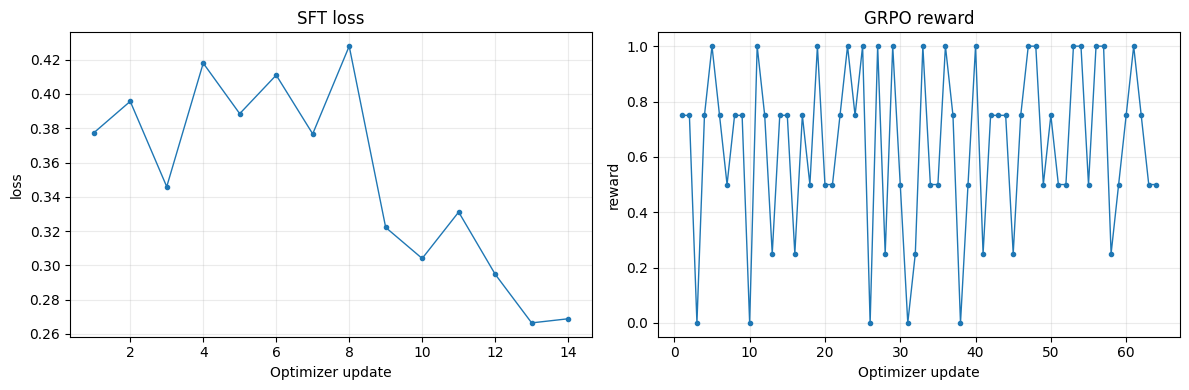

In [15]:
run(script='inspect_run.py')

import pandas as pd
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for stage, metric, ax in [('sft', 'loss', axes[0]), ('grpo', 'reward', axes[1])]:
    path = ROOT/'logs'/f'{stage}_metrics.jsonl'
    records = read(path) if path.exists() else []
    points = [r for r in records if r.get('event') == 'train_log' and metric in r]
    if points:
        frame = pd.DataFrame(points).drop_duplicates('current', keep='last').sort_values('current')
        ax.plot(frame['current'], frame[metric], marker='.', linewidth=1)
    else:
        ax.text(.5, .5, 'No logged points yet', ha='center', transform=ax.transAxes)
    ax.set(title=f'{stage.upper()} {metric}', xlabel='Optimizer update', ylabel=metric)
    ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(ROOT/'logs'/'training_curves.png', dpi=160)
plt.show()


## Final test: the same 64 questions for all student stages

Freeze evaluation settings before running. Base, SFT, and GRPO each answer the same 64 questions using the same plain-text prompt and greedy decoding. A single answer changes accuracy by 1.56 percentage points. Answer parse rate is reported separately; audit unparseable Base responses before interpreting a low score as low reasoning ability. MATH-500 is not run automatically.


In [16]:

RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    for stage in ['base', 'sft', 'grpo']:
        run('eval', '--stage', stage, '--split', 'test_gsm8k', '--eval-tokens', EVAL_TOKENS)
run(script='inspect_run.py')


Console log: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/logs/pipeline_eval_1792132180142179081.console.log
Running: /usr/bin/python3 -u pipeline.py eval --stage base --split test_gsm8k --eval-tokens 2048 --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001
I0000 00:00:1792132183.149207   78300 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792132183.222188   78300 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792132185.603087   78300 port.cc:153] oneDNN custom operations are on. You may see slig

In [17]:
report = ROOT/'eval'/'comparison.csv'
if report.exists():
    frame = pd.read_csv(report)
    from IPython.display import display
    print('Final test results:')
    display(frame[frame['split'] == 'test_gsm8k'])
    print('Development results:')
    display(frame[frame['split'] == 'dev'])
else:
    print('No evaluation report yet.')


Final test results:


,stage,split,n,accuracy_percent,answer_parse_percent,mean_tokens,mean_seconds,budget_hit_percent,eval_budget
0,base,test_gsm8k,64,3.12,3.12,166.7,6.43,0.00,2048
2,grpo,test_gsm8k,64,73.44,95.31,349.5,25.76,4.69,2048
4,sft,test_gsm8k,64,78.12,96.88,300.4,22.13,4.69,2048


Development results:


,stage,split,n,accuracy_percent,answer_parse_percent,mean_tokens,mean_seconds,budget_hit_percent,eval_budget
1,grpo,dev,32,84.38,96.88,325.1,23.86,6.25,2048
3,sft,dev,32,90.62,100.00,214.9,15.43,0.00,2048
